### Example 2: An internal wavemaker for waves on currents

In example 1 the waves came from an initial condition, which is fine for transient wave packets. But very often we want a steady stream of incoming waves, say a swell or a whole sea state, that keeps running through the current and bathymetry we care about. There are no inflow boundaries in WaCuBa (the domain is periodic with sponge layers), so the waves have to be made *inside* the domain by a source term $S(t,X)$:
$$
\begin{cases}
\partial_t \eta + \nabla_X\cdot(\bar{U}\eta) = \mathcal{G}(b)\varphi + S(t,X), \\
\partial_t \varphi + \bar{U}\cdot\nabla_X\varphi = -g\eta.
\end{cases}
$$
The question is how to pick $S$ so that it sends out exactly the wave we want, in one direction only, and nothing else. Below is a quick sketch of the construction, then two tests: one monochromatic wave and one directional spectrum.

### The 1D problem

Start simple: one dimension, constant current $U$ and constant depth $H$. Eliminating $\varphi$ gives
$$ (\partial_t + U\partial_x)^2\eta + gG(H)\eta = (\partial_t + U\partial_x)S. $$
With a time-harmonic source $S = \mathrm{Re}\{s(x)e^{-i\omega t}\}$ and $\eta = \mathrm{Re}\{\zeta(x)e^{-i\omega t}\}$ the relevant wavenumbers are the real roots $k_j$ of the dispersion relation
$$ D(k,\omega) = \sigma^2(k) - (\omega - Uk)^2 = 0, \qquad \sigma^2(k) = g|k|\tanh(H|k|). $$
With a current there are typically four of them (two with no current). Working out the causal Green's function with the residue theorem, the poles get pushed above or below the real axis depending on the sign of the group velocity $C_g = \mathrm{d}\omega/\mathrm{d}k$, and the $(\omega - Uk)$ factors cancel against the right-hand side. The upshot is pleasantly simple: away from a compactly supported source the field is a sum of plane waves,
$$ \zeta(x) = \sum_{j:\,C_g(k_j)>0} \frac{\widehat{s}(k_j)}{2C_g(k_j)}e^{ik_jx} \quad \text{(downstream of the source)}, \qquad \zeta(x) = -\sum_{j:\,C_g(k_j)<0}\frac{\widehat{s}(k_j)}{2C_g(k_j)}e^{ik_jx} \quad \text{(upstream)}, $$
where $\widehat{s}(k) = \int e^{-iky}s(y)\,\mathrm{d}y$. So each root radiates with strength $\widehat{s}(k_j)$ to the side its group velocity points to.

### Building the source

That tells us exactly what to do: if we want only the target wave $k^*$, we need $\widehat{s}(k_j) = 0$ at every other root and $\widehat{s}(k^*) = 2aC_g(k^*)$ to get amplitude $a$. The roots can be killed with a differential operator, since $\partial_x \to ik$ in Fourier space. Taking a smooth bump $B$ supported on $[x_c - W, x_c + W]$ and modulating it with the carrier,
$$ s(x) = \Lambda\, e^{ik^*(x - x_c)} \prod_{j}\frac{\partial_x - i(k_j - k^*)}{i(k^* - k_j)} B(x), \qquad B(x) = \exp\left(-\frac{1}{1 - ((x - x_c)/W)^2}\right), $$
gives $\widehat{s}(k) \propto \prod_j \frac{k - k_j}{k^* - k_j}\,\widehat{B}(k - k^*)$, which vanishes at all the unwanted roots and equals $\Lambda\int B$ at $k^*$. So
$$ \Lambda = \frac{2a\,|C_g(k^*)|}{\int B\,\mathrm{d}x}. $$
The bump has to be $C^\infty$, since we take up to three derivatives of it and any kink would leak energy everywhere. The derivatives are evaluated analytically.

### 2D and spectra

In 2D we just apply the 1D recipe along a beam: for a wave in direction $\theta$ we use the rotated coordinate $x' = (X - X_c)\cdot(\cos\theta, \sin\theta)$, the projected current $U_\mathrm{eff} = \bar U\cdot(\cos\theta,\sin\theta)$ in the dispersion relation, and a long smooth window across the beam so the source is a finite line. Since everything is linear, a spectral wavemaker is just a sum of such sources, one for each component $(k_j, \theta_j, a_j)$ with random phases. That's what `create_spectral_source` does.

The functions live in `wave_module.py`:
- `create_exact_unidirectional_source(X, Y, k, U, H, center, theta, a, ...)`: one wave
- `create_spectral_source(X, Y, k, theta, a, U, H, center, ...)`: a list of components
- `dispersion_roots`, `group_velocity` and `wave_frequency`: the 1D dispersion bits used above

Both return a function `F(t)` which is passed to `simulate_wave_system(..., source=F)`.

In [1]:
import sys
import os
sys.path.append(os.path.abspath('../src'))
import numpy as np
import matplotlib.pyplot as plt
import wave_module as wm
from scipy.ndimage import map_coordinates
from scipy.signal import hilbert

# Domain and resolution
Lx, Ly = 1000, 800
Nx, Ny = 320, 256        # dx = dy = 3.125 m, i.e. 8+ points per wavelength for the waves below
X, Y, dx, dy = wm.build_grid(Lx, Ly, Nx, Ny)
g = 9.81

# Flat bottom and a constant (slightly oblique) current
H = 10
b = H*np.ones_like(X)
U0 = (0.4, 0.15)
U = U0[0]*np.ones_like(X), U0[1]*np.ones_like(X)

# DN operator: flat bottom, so no need for the variable depth part
topo_data = wm.precompute_dtn_system(Lx, Ly, Nx, Ny, b, flat_bottom=True)

# Sponge layers: about two of the longest wavelengths (k = 0.12) on every side
d = 2*2*np.pi/0.12
sponge_frac = d/Ly
sigma_max = 1.0
sponge_sides = "lrtb"

dt = 0.1

# Source line and the box where we record the wave field
center = (220, 400)                       # centre of the source
src_width, src_length, src_taper = 60, 640, 80
box = (350, 550, 320, 480)                # x0, x1, y0, y1
in_box = (X > box[0]) & (X < box[1]) & (Y > box[2]) & (Y < box[3])
rows, cols = np.where(in_box.any(axis=1))[0], np.where(in_box.any(axis=0))[0]
box_slice = (slice(rows[0], rows[-1] + 1), slice(cols[0], cols[-1] + 1))
Xb, Yb = X[box_slice], Y[box_slice]

A few notes on the choices. The box sits between 130 and 330 m downstream of the source, well inside the region lit up by the source line and away from the sponges. The source line is 640 m long with an 80 m taper at each end, so the edges of the beam (and the diffraction from them) stay out of the box. The time step follows example 1: $\omega_{max} \approx \sqrt{g|k|_{max}} + |\bar U||k|_{max} \approx 4.4$, so $\Delta t\,\omega_{max} \approx 0.44$.

We record $\eta$ in the box every half second through the `callback` argument of `simulate_wave_system`, so we don't need to keep hundreds of full snapshots in memory. We also need a few helpers for the analysis:
- `record`: makes the callback (box, and optionally a line of points).
- `fit_amplitudes`: least-squares fit of $\sum_j \mathrm{Re}\{c_j e^{i(k_j\cdot(X - X_c) - \omega_j t)}\}$ to the recording, which gives the amplitude and phase of every component we asked for. With a long record the components separate nicely, since they differ in either frequency or direction.
- `wavenumber_spectrum` and `frequency_spectrum`: plain FFT spectra of the recording (Hann windowed in space or time), normalised so that they sum to the variance of $\eta$. For the wavenumber spectrum we use the analytic signal in time, so we can tell a wave going one way from one going the opposite way.

In [2]:
def record(every=5, t_start=0.0, line=None):
    # callback that stores eta in the box (and optionally along a line of (row, col) points)
    data = {"t": [], "eta": [], "line": []}
    def callback(t, eta, phi):
        if t > t_start and round(t/dt) % every == 0:
            data["t"].append(t)
            data["eta"].append(eta[box_slice].copy())
            if line is not None:
                data["line"].append(map_coordinates(eta, line, order=3, mode="grid-wrap"))
    return data, callback


def plane_waves(k, theta, omega, t):
    # exp(i(k.(X - X_c) - omega t)) on the box, shape (n_components, n_points)
    kx, ky = k*np.cos(theta), k*np.sin(theta)
    E = np.exp(1j*(np.outer(kx, Xb.ravel() - center[0]) + np.outer(ky, Yb.ravel() - center[1])))
    return E*np.exp(-1j*omega*t)[:, None]


def fit_amplitudes(t_rec, eta_rec, k, theta, omega):
    # least squares for eta = sum_j c_j e_j + conj(c_j e_j), via the normal equations
    n = len(k)
    M = np.zeros((2*n, 2*n), dtype=complex)
    rhs = np.zeros(2*n, dtype=complex)
    for t, eta in zip(t_rec, eta_rec):
        Phi = plane_waves(k, theta, omega, t)
        Phi = np.vstack([Phi, Phi.conj()])
        M += Phi.conj() @ Phi.T
        rhs += Phi.conj() @ eta.ravel()
    c = np.linalg.solve(M, rhs)[:n]
    return 2*np.abs(c), np.angle(c)


def wavenumber_spectrum(eta_rec, pad=4):
    # Time averaged |FFT|^2 over the box with a 2D Hann window (zero padded to look smoother).
    # We use the analytic signal in time, which only keeps positive frequencies, so a wave
    # going in direction k only shows up at +k and not also at -k.
    eta_a = np.conj(hilbert(eta_rec, axis=0))   # conj, since our waves go like exp(-i omega t)
    nt = len(eta_a)
    eta_a = eta_a[nt//10:-nt//10]        # drop the ends, where the Hilbert transform is a bit off
    ny, nx = eta_a.shape[1:]
    w = np.outer(np.hanning(ny), np.hanning(nx))
    Ny_p, Nx_p = pad*ny, pad*nx
    P = np.mean(np.abs(np.fft.fft2(eta_a*w, s=(Ny_p, Nx_p)))**2, axis=0)/(2*np.sum(w**2)*Nx_p*Ny_p)
    kx = 2*np.pi*np.fft.fftfreq(Nx_p, dx)
    ky = 2*np.pi*np.fft.fftfreq(Ny_p, dy)
    return np.fft.fftshift(kx), np.fft.fftshift(ky), np.fft.fftshift(P)


def frequency_spectrum(t_rec, eta_rec):
    # one-sided spectrum in omega, averaged over all points in the box
    nt = len(t_rec)
    w = np.hanning(nt)[:, None, None]
    P = np.mean(np.abs(np.fft.rfft(eta_rec*w, axis=0))**2, axis=(1, 2))/np.sum(w**2)/nt
    P[1:] *= 2
    om = 2*np.pi*np.fft.rfftfreq(nt, t_rec[1] - t_rec[0])
    return om, P


def input_field(t_rec, k, theta, a, omega, phase):
    # what the box should see if the wavemaker were perfect
    c = a*np.exp(1j*phase)
    return np.array([np.real(c @ plane_waves(k, theta, omega, t)).reshape(Xb.shape) for t in t_rec])


def show_field(eta, title, vmax):
    fig, ax = plt.subplots(figsize=(9, 6.5))
    c = ax.pcolormesh(X, Y, eta, cmap="RdBu_r", vmin=-vmax, vmax=vmax, shading="auto")
    fig.colorbar(c, ax=ax, label=r"$\eta$ [m]", shrink=0.8)
    ax.add_patch(plt.Rectangle((box[0], box[2]), box[1] - box[0], box[3] - box[2], fill=False, ec="k", lw=1.5))
    ax.text(box[0], box[3] + 8, "recording box", fontsize=9)
    d_sp = sponge_frac*min(Lx, Ly)
    ax.add_patch(plt.Rectangle((d_sp, d_sp), Lx - 2*d_sp, Ly - 2*d_sp, fill=False, ec="0.4", ls="--", lw=1))
    ax.plot(*center, "k+", ms=10)
    ax.set_aspect("equal")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_title(title)
    plt.show()

### Test 1: one monochromatic wave

We ask for a wave with $\lambda = 40$ m ($k = 0.157$), amplitude $a = 0.5$ m, going $20°$ up from the $x$-axis. The current has a component along the beam, so along the beam there are four roots of the dispersion relation. Let's look at them first, and at which ones the source has to kill.

In [3]:
k1, theta1, a1 = 2*np.pi/40, np.deg2rad(20), 0.5

U_eff = U0[0]*np.cos(theta1) + U0[1]*np.sin(theta1)
omega1 = wm.wave_frequency(k1, theta1, U0, H)
roots = wm.dispersion_roots(omega1, U_eff, H)
print(f"U_eff = {U_eff:.3f} m/s, omega = {omega1:.4f} rad/s, period = {2*np.pi/omega1:.2f} s")
for kj in roots:
    cg = wm.group_velocity(kj, omega1, U_eff, H)
    tag = "<- target" if np.isclose(kj, k1) else ("killed" if abs(kj) < np.pi/dx else "killed (not resolved on the grid anyway)")
    print(f"  k = {kj:9.4f}   C_g = {cg:7.3f}   {tag}")

U_eff = 0.427 m/s, omega = 1.2559 rad/s, period = 5.00 s
  k =  -47.6972   C_g =   0.200   killed (not resolved on the grid anyway)
  k =   -0.1906   C_g =  -3.674   killed
  k =    0.1571   C_g =   5.241   <- target
  k =   59.4932   C_g =   0.224   killed (not resolved on the grid anyway)


The negative root close to $-k^*$ is the important one: that's the wave that would run upstream if we didn't cancel it. The two big roots are very short waves living on the current (they come from $\omega \approx Uk$); our grid can't resolve them, but cancelling them costs nothing.

Now set up the source and run for 250 s. The source ramps up over three periods, and after about 100 s the front has passed the box, so we record from $t = 120$ s. We also record $\eta$ along the centre line of the beam, from 200 m behind the source to 500 m in front of it.

In [4]:
F1 = wm.create_exact_unidirectional_source(X, Y, k1, U0, H, center, theta=theta1, a=a1,
                                           width=src_width, length=src_length, taper=src_taper)

# points on the beam centre line, as (row, col) for map_coordinates
s_line = np.arange(-200, 500, 2.0)
line_pts = np.array([(center[1] + s_line*np.sin(theta1))/dy, (center[0] + s_line*np.cos(theta1))/dx])

rec1, cb1 = record(every=5, t_start=120, line=line_pts)
t_snaps, eta_snaps, _, _ = wm.simulate_wave_system(
    Lx, Ly, Nx, Ny, 250, dt,
    np.zeros_like(X), np.zeros_like(X),
    U, topo_data,
    sponge_frac=sponge_frac, sponge_sides=sponge_sides, sigma_max=sigma_max,
    snapshot_interval=50,
    source=F1, callback=cb1,
)
t_rec1, eta_rec1, line_rec1 = np.array(rec1["t"]), np.array(rec1["eta"]), np.array(rec1["line"])

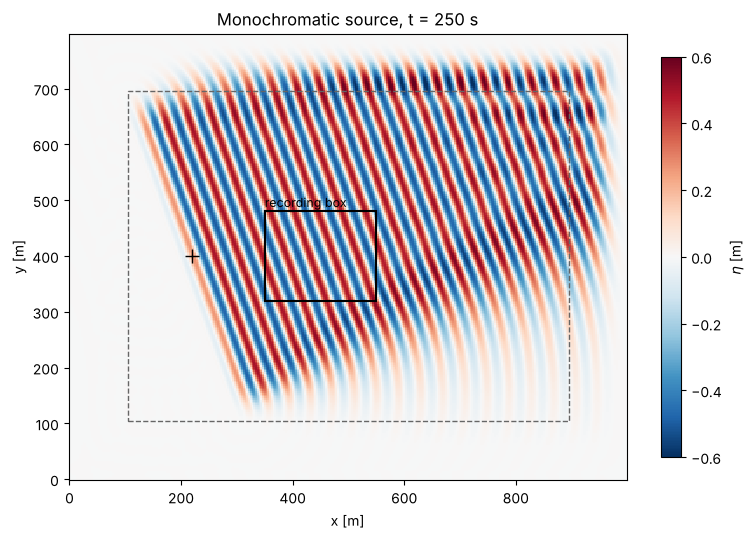

In [5]:
show_field(eta_snaps[-1], f"Monochromatic source, t = {t_snaps[-1]:.0f} s", vmax=1.2*a1)

That looks like a clean plane wave going up and to the right, with a calm region behind the source. To make it quantitative, let's look along the centre line of the beam: the envelope (max of $|\eta|$ over the last 30 s) should be $a$ downstream and zero upstream.

That looks like a clean plane wave heading up and to the right, with calm water behind the source. To make it quantitative, look along the centre line of the beam. The top panel compares $\eta$ at the final time with the wave we asked for, $a\cos(k^*s - \omega t)$, where $s$ is the distance along the beam from the source centre. The bottom panel shows the amplitude at the forcing frequency, $|2\langle \eta\, e^{i\omega t}\rangle_t|$, over the recording: it should be $a$ downstream and $0$ upstream.

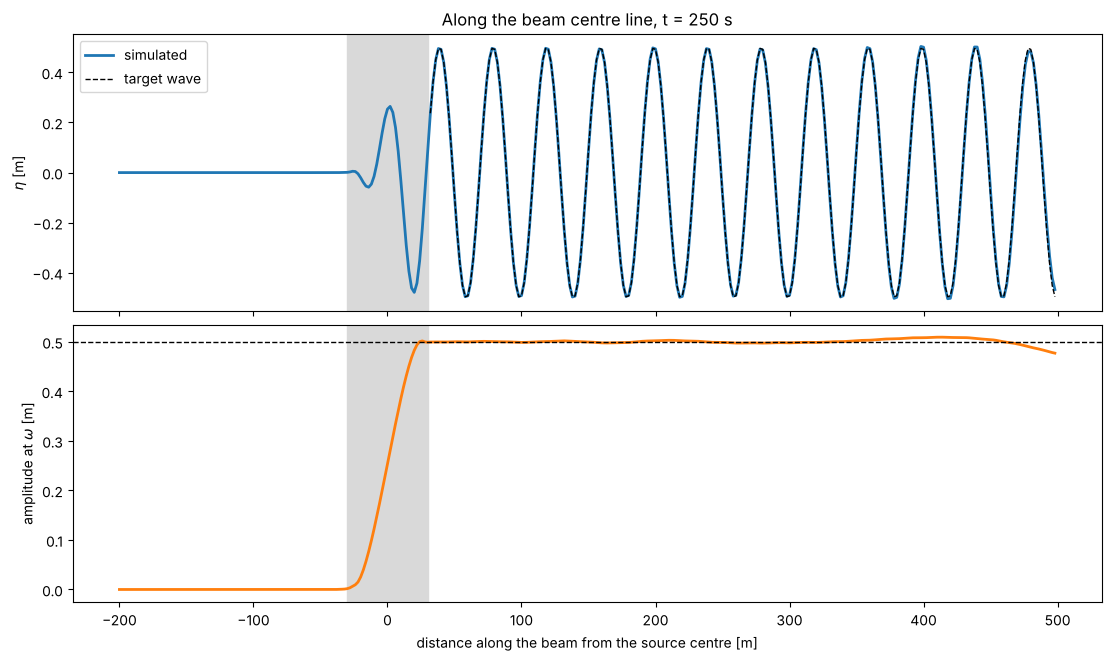

mean amplitude downstream: 0.5006 m (asked for 0.5)
mean amplitude upstream:   1.28e-04 m


In [6]:
amp_line = np.abs(2*np.mean(line_rec1*np.exp(1j*F1.omega*t_rec1)[:, None], axis=0))
target = a1*np.cos(k1*s_line - F1.omega*t_rec1[-1])

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, layout="constrained")
ax = axes[0]
ax.plot(s_line, line_rec1[-1], lw=2, label="simulated")
ax.plot(s_line[s_line > 30], target[s_line > 30], "k--", lw=1, label="target wave")
ax.set_ylabel(r"$\eta$ [m]")
ax.legend(loc="upper left")
ax.set_title(f"Along the beam centre line, t = {t_rec1[-1]:.0f} s")
ax = axes[1]
ax.plot(s_line, amp_line, lw=2, color="C1")
ax.axhline(a1, color="k", ls="--", lw=1)
ax.set_ylabel(r"amplitude at $\omega$ [m]")
ax.set_xlabel("distance along the beam from the source centre [m]")
for ax in axes:
    ax.axvspan(-src_width/2, src_width/2, color="0.85", zorder=0)
plt.show()

up = (s_line > -150) & (s_line < -50)
down = (s_line > 100) & (s_line < 400)
print(f"mean amplitude downstream: {amp_line[down].mean():.4f} m (asked for {a1})")
print(f"mean amplitude upstream:   {amp_line[up].mean():.2e} m")

The grey band is the source. Downstream we get the right amplitude and phase, and upstream there's essentially nothing; the cancellation of the upstream root works as advertised. The small drop in amplitude at the far end is the finite length of the source line showing up (the diffracted edges of the beam start to reach the centre line).

Now the spectral view of the same thing, which is the check we'll use for the spectrum below. From the recording in the box we compute the wavenumber spectrum (averaged over time) and the frequency spectrum (averaged over the box). There should be one peak at $\mathbf{k}^* = k^*(\cos\theta, \sin\theta)$ and one at $\omega$, and nothing at $-\mathbf{k}^*$ or anywhere else.

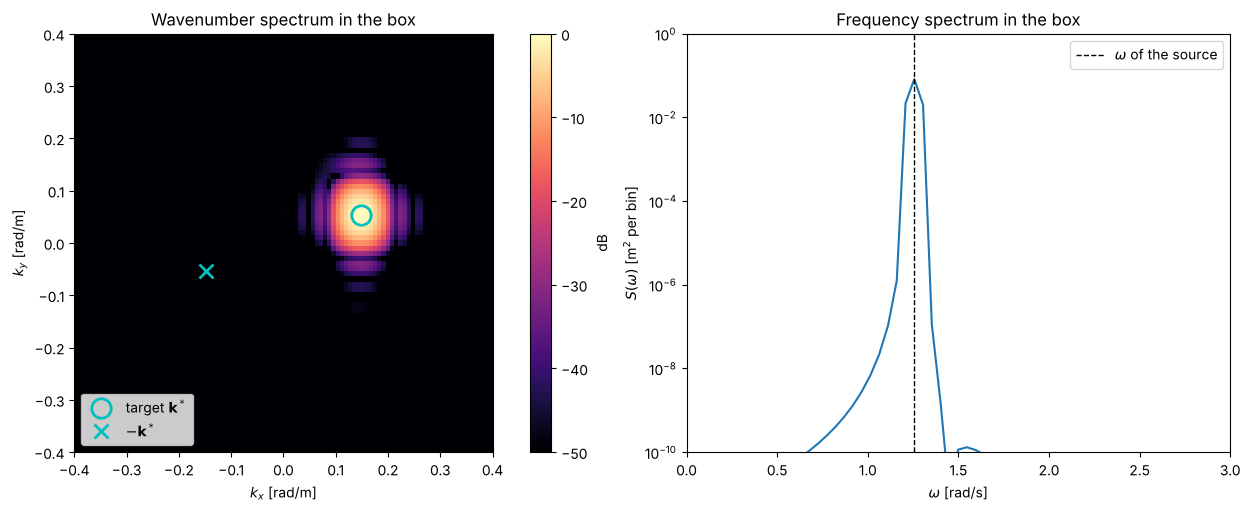

fitted amplitude 0.4997 m (asked for 0.5), phase +0.002 rad (asked for 0)
variance in the box 0.12487 m^2, a^2/2 = 0.12500 m^2


In [7]:
kxs, kys, Pk = wavenumber_spectrum(eta_rec1)
om, Pw = frequency_spectrum(t_rec1, eta_rec1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
ax = axes[0]
c = ax.pcolormesh(kxs, kys, 10*np.log10(Pk/Pk.max()), vmin=-50, vmax=0, cmap="magma", shading="auto")
fig.colorbar(c, ax=ax, label="dB")
ax.plot(k1*np.cos(theta1), k1*np.sin(theta1), "o", mfc="none", mec="c", ms=14, mew=2, label=r"target $\mathbf{k}^*$")
ax.plot(-k1*np.cos(theta1), -k1*np.sin(theta1), "x", color="c", ms=10, mew=2, label=r"$-\mathbf{k}^*$")
ax.set_xlim(-0.4, 0.4); ax.set_ylim(-0.4, 0.4); ax.set_aspect("equal")
ax.set_xlabel(r"$k_x$ [rad/m]"); ax.set_ylabel(r"$k_y$ [rad/m]")
ax.set_title("Wavenumber spectrum in the box")
ax.legend(loc="lower left")
ax = axes[1]
ax.semilogy(om, Pw, lw=1.5)
ax.axvline(F1.omega, color="k", ls="--", lw=1, label=r"$\omega$ of the source")
ax.set_xlim(0, 3); ax.set_ylim(1e-10, 1)
ax.set_xlabel(r"$\omega$ [rad/s]"); ax.set_ylabel(r"$S(\omega)$ [m$^2$ per bin]")
ax.set_title("Frequency spectrum in the box")
ax.legend()
plt.show()

a_fit, ph_fit = fit_amplitudes(t_rec1, eta_rec1, np.array([k1]), np.array([theta1]), np.array([F1.omega]))
print(f"fitted amplitude {a_fit[0]:.4f} m (asked for {a1}), phase {ph_fit[0]:+.3f} rad (asked for 0)")
print(f"variance in the box {eta_rec1.var():.5f} m^2, a^2/2 = {a1**2/2:.5f} m^2")

One peak in each, right where it should be, nothing at $-\mathbf{k}^*$, and the least squares fit gives back the amplitude and phase we put in. The wavenumber peak is fairly wide simply because the box is only 200 m across, so the resolution is about $2\pi/200 \approx 0.03$ rad/m.

### Test 2: a directional spectrum

Now for the real test. We take a small discrete spectrum: 5 wavenumbers between 0.12 and 0.20 rad/m (wavelengths from 31 to 52 m), times 5 directions between $-24°$ and $24°$. The amplitudes follow a Gaussian in $k$ around $k_p = 0.16$ and a $\cos^4\theta$ spreading, scaled so the significant wave height is $H_s = 4\sqrt{\sum_j a_j^2/2} \approx 1.4$ m. The phases are random. Every component goes through the same source line, each with its own beam.

25 components, Hs = 1.41 m


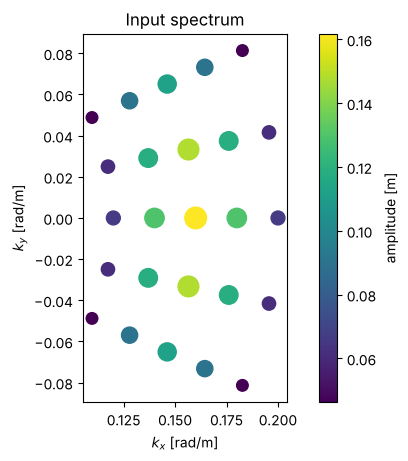

In [8]:
k_vals = np.array([0.12, 0.14, 0.16, 0.18, 0.20])
th_vals = np.deg2rad([-24, -12, 0, 12, 24])
KK, TT = np.meshgrid(k_vals, th_vals)
AA = np.exp(-0.5*((KK - 0.16)/0.03)**2)*np.cos(TT)**4
AA *= 0.5/np.sqrt(np.sum(AA**2))
k_in, th_in, a_in = KK.ravel(), TT.ravel(), AA.ravel()
print(f"{len(k_in)} components, Hs = {4*np.sqrt(np.sum(a_in**2/2)):.2f} m")

F2 = wm.create_spectral_source(X, Y, k_in, th_in, a_in, U0, H, center,
                               width=src_width, length=src_length, taper=src_taper,
                               ramp_periods=5, seed=1)

fig, ax = plt.subplots(figsize=(5.5, 4.5), layout="constrained")
sc = ax.scatter(k_in*np.cos(th_in), k_in*np.sin(th_in), s=1500*a_in, c=a_in, cmap="viridis")
fig.colorbar(sc, ax=ax, label="amplitude [m]")
ax.set_aspect("equal")
ax.set_xlabel(r"$k_x$ [rad/m]"); ax.set_ylabel(r"$k_y$ [rad/m]")
ax.set_title("Input spectrum")
plt.show()

The slowest component (k = 0.20) has a group velocity of about 4 m/s, so it takes roughly 80 s to cross the box. With a ramp over five of the longest periods we start recording at $t = 150$ s and record for 250 s. That's long enough for all 25 components to be told apart in the fit.

In [9]:
rec2, cb2 = record(every=5, t_start=150)
t_snaps2, eta_snaps2, _, _ = wm.simulate_wave_system(
    Lx, Ly, Nx, Ny, 400, dt,
    np.zeros_like(X), np.zeros_like(X),
    U, topo_data,
    sponge_frac=sponge_frac, sponge_sides=sponge_sides, sigma_max=sigma_max,
    snapshot_interval=50,
    source=F2, callback=cb2,
)
t_rec2, eta_rec2 = np.array(rec2["t"]), np.array(rec2["eta"])

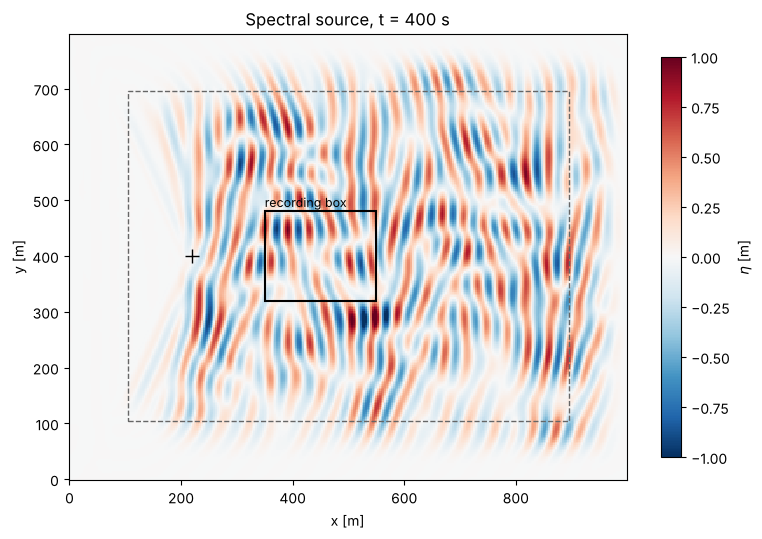

In [10]:
show_field(eta_snaps2[-1], f"Spectral source, t = {t_snaps2[-1]:.0f} s", vmax=1.0)

Looks like a short-crested sea, as it should. Now the comparison. For a fair comparison of the spectra, we take the *input* wave field, $\sum_j a_j\cos(\mathbf{k}_j\cdot(X - X_c) - \omega_j t + \phi_j)$, evaluate it on the same box at the same times, and push it through exactly the same spectral estimate as the simulation. Then any difference is down to the wavemaker and not the windowing.

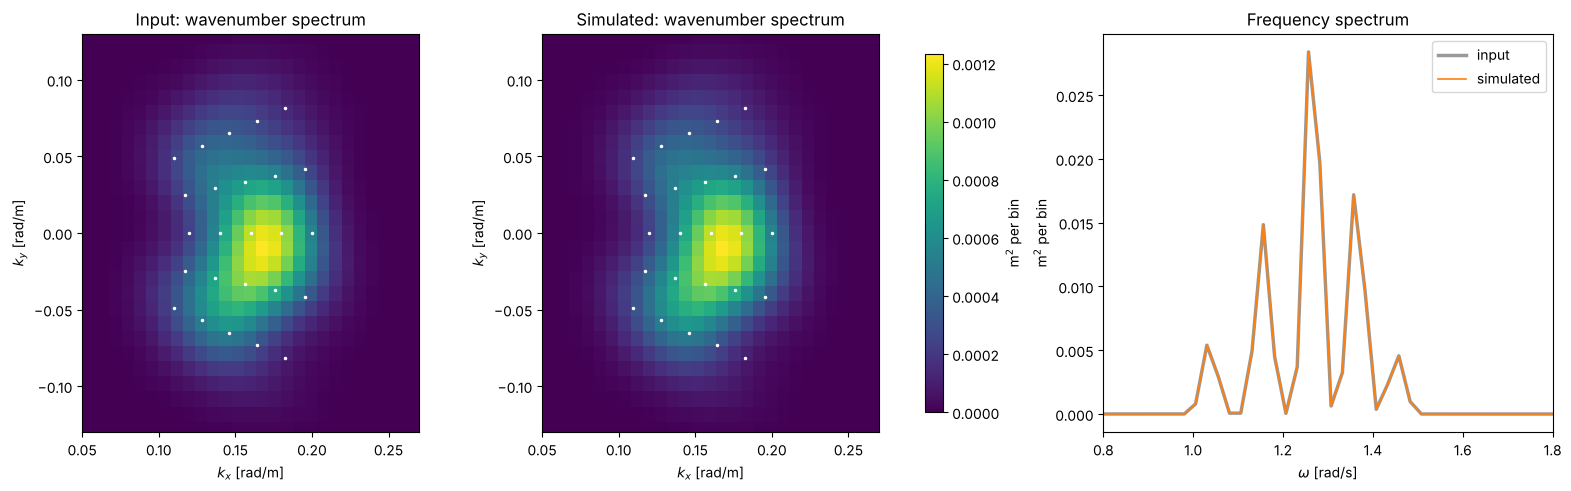

variance in the box: simulated 0.1246 m^2, input 0.1246 m^2, sum a^2/2 = 0.1250 m^2
relative L2 difference of the wavenumber spectra: 0.001
relative L2 difference of the frequency spectra:  0.001


In [11]:
eta_in2 = input_field(t_rec2, k_in, th_in, a_in, F2.omega, F2.phase)

kxs, kys, Pk_sim = wavenumber_spectrum(eta_rec2)
_, _, Pk_in = wavenumber_spectrum(eta_in2)
om, Pw_sim = frequency_spectrum(t_rec2, eta_rec2)
_, Pw_in = frequency_spectrum(t_rec2, eta_in2)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), layout="constrained")
vmax = Pk_in.max()
for ax, P, title in zip(axes[:2], [Pk_in, Pk_sim], ["Input", "Simulated"]):
    c = ax.pcolormesh(kxs, kys, P, vmin=0, vmax=vmax, cmap="viridis", shading="auto")
    ax.plot(k_in*np.cos(th_in), k_in*np.sin(th_in), "w.", ms=3)
    ax.set_xlim(0.05, 0.27); ax.set_ylim(-0.13, 0.13); ax.set_aspect("equal")
    ax.set_xlabel(r"$k_x$ [rad/m]"); ax.set_ylabel(r"$k_y$ [rad/m]")
    ax.set_title(f"{title}: wavenumber spectrum")
fig.colorbar(c, ax=axes[:2], label=r"m$^2$ per bin", shrink=0.9)
ax = axes[2]
ax.plot(om, Pw_in, "k", lw=2.5, alpha=0.4, label="input")
ax.plot(om, Pw_sim, "C1", lw=1.2, label="simulated")
ax.set_xlim(0.8, 1.8)
ax.set_xlabel(r"$\omega$ [rad/s]"); ax.set_ylabel(r"m$^2$ per bin")
ax.set_title("Frequency spectrum")
ax.legend()
plt.show()

print(f"variance in the box: simulated {eta_rec2.var():.4f} m^2, input {eta_in2.var():.4f} m^2, sum a^2/2 = {np.sum(a_in**2/2):.4f} m^2")
print(f"relative L2 difference of the wavenumber spectra: {np.linalg.norm(Pk_sim - Pk_in)/np.linalg.norm(Pk_in):.3f}")
print(f"relative L2 difference of the frequency spectra:  {np.linalg.norm(Pw_sim - Pw_in)/np.linalg.norm(Pw_in):.3f}")

The two wavenumber spectra are hard to tell apart, and the frequency spectra lie on top of each other. The white dots are the input wavenumbers. The box is too small to resolve the individual components in space, but the frequency spectrum (from 250 s of data) does pick out the different $k$'s, and the fit below separates the directions too.

Finally the component by component check: fit all 25 amplitudes and phases to the recording and compare with what went into the source.

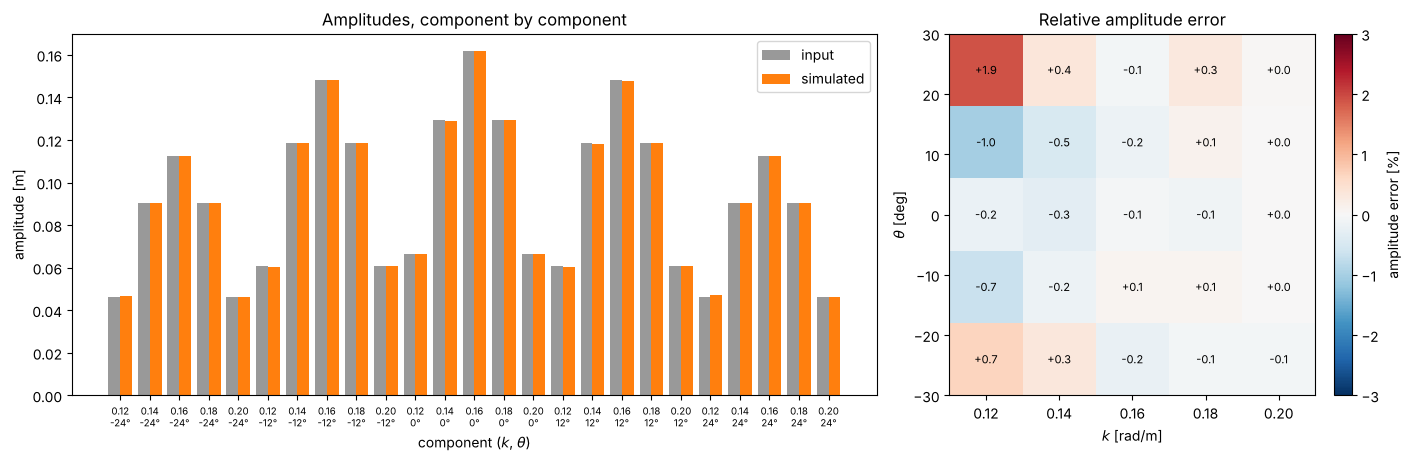

amplitude error: max 1.9%, mean 0.3% (components above 10% of the peak)
phase error:     max 0.015 rad
fraction of the variance in the box explained by the 25 input components: 0.9998


In [12]:
a_out, ph_out = fit_amplitudes(t_rec2, eta_rec2, k_in, th_in, F2.omega)
dphase = np.angle(np.exp(1j*(ph_out - F2.phase)))

fit_field = input_field(t_rec2, k_in, th_in, a_out, F2.omega, ph_out)
explained = 1 - np.var(eta_rec2 - fit_field)/np.var(eta_rec2)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), layout="constrained", gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
idx = np.arange(len(k_in))
ax.bar(idx - 0.2, a_in, 0.4, label="input", color="0.6")
ax.bar(idx + 0.2, a_out, 0.4, label="simulated", color="C1")
ax.set_xticks(idx, [f"{k:.2f}\n{np.rad2deg(t):.0f}°" for k, t in zip(k_in, th_in)], fontsize=7)
ax.set_xlabel(r"component ($k$, $\theta$)"); ax.set_ylabel("amplitude [m]")
ax.set_title("Amplitudes, component by component")
ax.legend()
ax = axes[1]
err = 100*(a_out - a_in)/a_in
c = ax.pcolormesh(k_vals, np.rad2deg(th_vals), err.reshape(KK.shape), cmap="RdBu_r", vmin=-3, vmax=3, shading="nearest")
for kk, tt, e in zip(k_in, np.rad2deg(th_in), err):
    ax.text(kk, tt, f"{e:+.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(c, ax=ax, label="amplitude error [%]")
ax.set_xlabel(r"$k$ [rad/m]"); ax.set_ylabel(r"$\theta$ [deg]")
ax.set_title("Relative amplitude error")
plt.show()

rel = np.abs(a_out - a_in)/a_in
big = a_in > 0.1*a_in.max()
print(f"amplitude error: max {100*rel[big].max():.1f}%, mean {100*rel[big].mean():.1f}% (components above 10% of the peak)")
print(f"phase error:     max {np.abs(dphase[big]).max():.3f} rad")
print(f"fraction of the variance in the box explained by the 25 input components: {explained:.4f}")

The amplitudes and phases come back within a few percent, and the 25 input components explain basically all of the variance in the box, so the wavemaker isn't making anything we didn't ask for.

### Wrapping up

The spectral wavemaker does what it should, at least in this simple setting with a flat bottom and constant current. Some things to keep in mind when using it:
- The theory is for constant current and depth at the source, so put the source where $\bar U$ and $b$ are (close to) uniform, and let the waves run into the interesting region from there.
- The line source is finite, so there's a "lit" region downstream of it. For wide directional spreads either make the line longer or put the region of interest closer to the source.
- Components that are blocked by the current ($\omega \le 0$), or whose group velocity points backwards, raise an error.
- The support width along the beam (`width`) is a free parameter. About one or two wavelengths works well; very narrow supports need a fine grid to resolve the derivatives of the bump.